**Real-world question:** How much atmospheric CO₂ concentration above an illustrative
**315 ppm baseline** accumulated over the historical observation period?

**Your deliverables:** (1) a data-quality summary, (2) a numerical result with correct
units, (3) a cumulative-area chart, and (4) a short interpretation that explains a limitation.

**Important:** An integral of concentration over time is measured in **ppm·years**.
It is **not** a measure of tonnes of emissions, atmospheric mass, or total emitted CO₂.
The baseline of 315 ppm is illustrative, not an official environmental threshold.

## Step 1 — Import the tools and audit all observations
    Check the time span and the 59 missing observations before making any calculation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Works when you launch Jupyter from the repository root or notebooks/ folder.
def data_path(filename):
    # Search for the data folder from the current
    # working directory up to the repository root.
    for folder in [Path.cwd(), *Path.cwd().parents]:
        candidate = folder / "data" / filename

        if candidate.is_file():
            return candidate

    raise FileNotFoundError(
        f"Cannot find {filename}. "
        f"Current directory: {Path.cwd()}"
    )

plt.rcParams.update({'figure.figsize': (11, 4.5), 'axes.grid': True,
                     'grid.alpha': 0.25, 'figure.dpi': 105})

from scipy.integrate import trapezoid, simpson, cumulative_trapezoid

In [2]:
df = (pd.read_csv(data_path('MaunaLoa_CO2_Full.csv'), parse_dates=['date'])
        .set_index('date').sort_index())
assert df.index.is_unique and df.index.is_monotonic_increasing
assert len(df) == 2284, 'Please use the supplied full historical dataset.'
assert int(df['co2_ppm'].isna().sum()) == 59
print('Rows:', len(df), '| Missing:', df['co2_ppm'].isna().sum())
print('Period:', df.index.min().date(), 'to', df.index.max().date())
display(df.head())

Rows: 2284 | Missing: 59
Period: 1958-03-29 to 2001-12-29


,co2_ppm
date,
1958-03-29,316.1
1958-04-05,317.3
1958-04-12,317.6
1958-04-19,317.5
1958-04-26,316.4


Missing share (%): 2.58
Observed minimum / maximum (ppm): 313.0 / 373.9


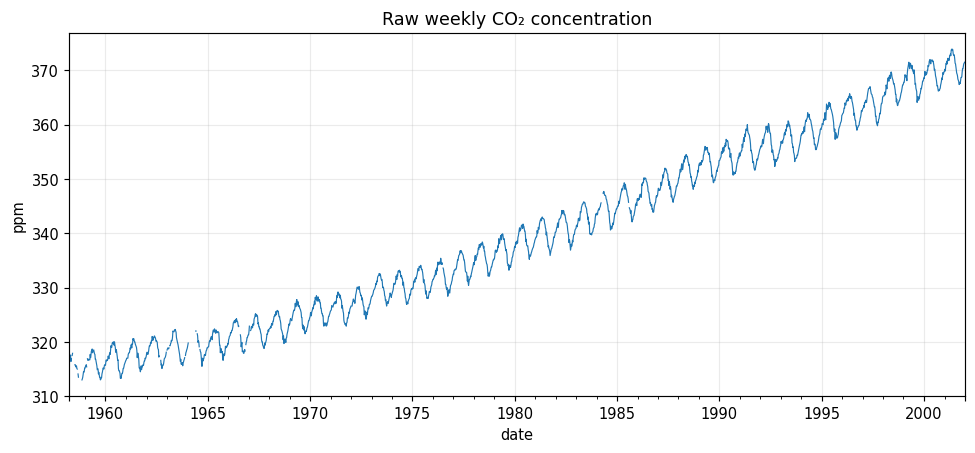

In [3]:
print('Missing share (%):', round(100 * df.co2_ppm.isna().mean(), 2))
print('Observed minimum / maximum (ppm):', df.co2_ppm.min(), '/', df.co2_ppm.max())
df.co2_ppm.plot(title='Raw weekly CO₂ concentration', lw=0.8)
plt.ylabel('ppm')
plt.show()

## Step 2 — Reconstruct interior gaps using dates
    We use pandas time interpolation to estimate **missing interior observations**.
    This is a documented analytical choice, not a claim that the missing readings are known.
    Keep `df['co2_ppm']` unchanged for traceability.

Values estimated: 59
Missing after interpolation: 0


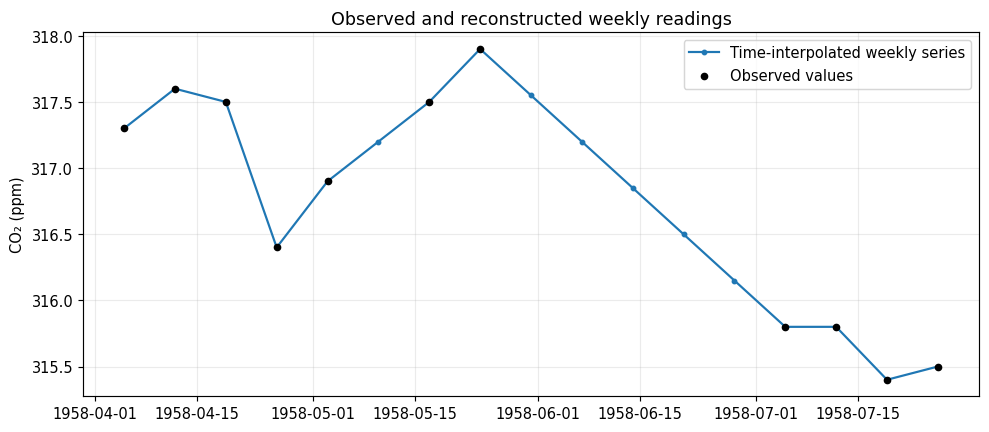

In [4]:
co2_filled = df.co2_ppm.interpolate(method='time', limit_area='inside')
assert co2_filled.notna().all(), 'Investigate any unfilled endpoint gaps.'
print('Values estimated:', int(df.co2_ppm.isna().sum()))
print('Missing after interpolation:', int(co2_filled.isna().sum()))

# Plot a short interval so interpolation is visible.
window = slice('1958-04-01', '1958-07-31')
plt.plot(co2_filled.loc[window].index, co2_filled.loc[window], '-o',
         ms=3, label='Time-interpolated weekly series')
plt.scatter(df.loc[window].index, df.loc[window, 'co2_ppm'],
            color='black', s=18, label='Observed values', zorder=3)
plt.ylabel('CO₂ (ppm)')
plt.title('Observed and reconstructed weekly readings')
plt.legend()
plt.show()

## Step 3 — Integrate using **actual elapsed years**
    `trapezoid(y, x=t)` uses the real date spacing; this is safer than assuming a
    constant `dx`. We calculate the **positive part** of the concentration anomaly.

In [5]:
baseline_ppm = 315.0
elapsed_years = (df.index - df.index[0]).days.to_numpy() / 365.2425
signed_anomaly = co2_filled.to_numpy() - baseline_ppm
above_baseline = np.maximum(signed_anomaly, 0.0)

area_ppm_years = trapezoid(above_baseline, x=elapsed_years)
signed_area = trapezoid(signed_anomaly, x=elapsed_years)
print(f'Area ABOVE {baseline_ppm:g} ppm: {area_ppm_years:,.2f} ppm·years')
print(f'Signed anomaly integral: {signed_area:,.2f} ppm·years')
assert 1000 < area_ppm_years < 1200, 'Check units, dates and baseline.'

Area ABOVE 315 ppm: 1,079.53 ppm·years
Signed anomaly integral: 1,078.58 ppm·years


## Step 4 — Plot cumulative accumulated anomaly
    A cumulative curve answers **when** most of the accumulated area was added.

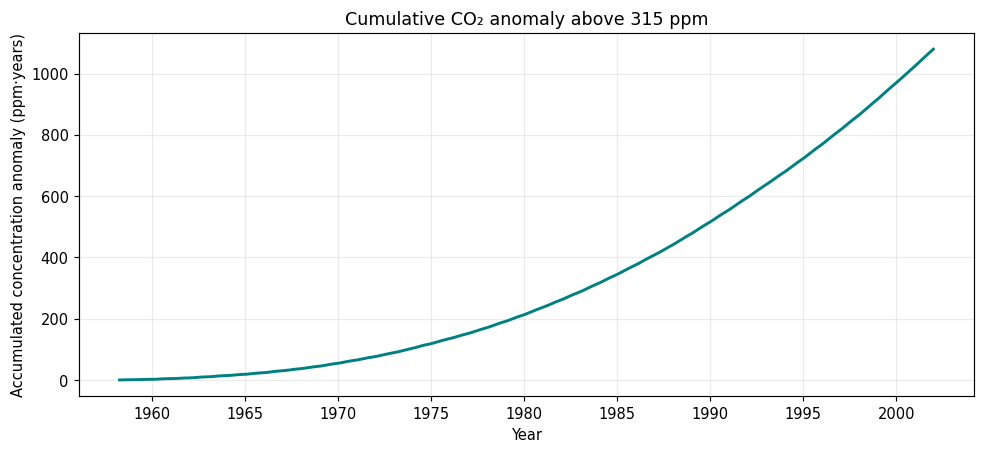

Final cumulative value: 1079.53


In [6]:
cumulative_area = cumulative_trapezoid(above_baseline, x=elapsed_years, initial=0)
fig, ax = plt.subplots()
ax.plot(df.index, cumulative_area, color='teal', lw=2)
ax.set(title='Cumulative CO₂ anomaly above 315 ppm',
       xlabel='Year', ylabel='Accumulated concentration anomaly (ppm·years)')
plt.show()
print('Final cumulative value:', round(cumulative_area[-1], 2))

## Step 5 — Compare numerical methods
    `simpson` and `trapezoid` are two numerical approximations. Agreement does not
    remove **measurement uncertainty** or uncertainty from imputed values.

In [7]:
simpson_area = simpson(above_baseline, x=elapsed_years)
method_comparison = pd.DataFrame({
    'method': ['trapezoid', 'simpson'],
    'area_ppm_years': [area_ppm_years, simpson_area]
})
display(method_comparison.round(2))
print('Difference:', round(abs(simpson_area - area_ppm_years), 4), 'ppm·years')

,method,area_ppm_years
0,trapezoid,1079.53
1,simpson,1079.51


Difference: 0.0239 ppm·years


## Your investigation — complete and discuss
    **A. Baseline sensitivity:** Recalculate the accumulated positive anomaly using
    **320 ppm** instead of 315 ppm. How much does your answer change, and why?

    **B. Equal-length periods:** Compare 1960–1970 with 1990–2000. Which period
    contributes more accumulated anomaly? Use the same baseline and time units.

    **C. Interpretation (3–4 sentences):** Explain your result, the interpolation
    decision, the units, and why the number is **not** total emissions.

    **Extension:** What changes if you integrate the **signed** anomaly instead of
    clipping values below the baseline to zero?

In [ ]:
# YOUR TURN — edit and run this cell.
# 1. Change baseline_ppm from 315 to 320 and recompute the area.
# 2. Select the two comparison periods using .loc[...].
# 3. Build a 2-row comparison DataFrame.
# Hint: compute time coordinates separately for each selected period.